# 09 - Hourly/monthly post-processing, normalization, and plots

This notebook performs post-processing over previously generated outputs, including normalization, time aggregation, and plot generation. It reads the results of notebook 02 (parametric run, which keeps the CSV files of its simulations) and notebook 07 (optimisation, which keeps those of its non-dominated solutions), so run those two notebooks first.

In practical terms, we will move through preparation, configuration, execution, and verification so every transition in the workflow stays explicit.
As the notebook progresses, each code cell is introduced with context first, then the call itself, and finally quick guidance on how to interpret the result.

Workflow roadmap:
- Preparation: imports, path configuration, and baseline model loading.
- Configuration: output selection, parameter definitions, and problem setup.
- Execution and review: simulation or optimization calls followed by targeted checks.

Main classes, methods, and functions used in this notebook:
- `ParametricSimulation.load_outputs_parametric`
- `ParametricSimulation.normalize_outputs`
- `OptimisationSimulation.load_outputs_optimisation`
- `OptimisationSimulation.plot_parallel_coordinates`
- `FileNotFoundError`
- `parametric.load_outputs_parametric`
- `parametric.normalize_outputs`
- `parametric.get_hourly_df`
- `parametric.get_monthly_df`

Narrative structure used in this notebook:
- Each code cell is preceded by an explanatory markdown block.
- Section headings are contextual to the current notebook and execution block.
- Key arguments are described before they are used in code.
- Execution-oriented cells may include a follow-up markdown note to help interpret results.

## Post-processing: import workflow dependencies

We start by importing the APIs required for this notebook block.

Keeping imports explicit at the top of each topic notebook makes selective reruns safer when you jump between sections of the series.

What to verify right after running this cell:
- Review execution output and proceed when values look consistent with the workflow intent.

In [1]:
from pathlib import Path

from IPython.display import Image, display
from accim.parametric_and_optimisation.main import ParametricSimulation, OptimisationSimulation


## Post-processing: locate latest output files

This cell locates the most recent result files of notebooks 02 and 07. The JSON files are used because they keep the names of the parameters and outputs, which some methods need.

The results are loaded into new objects, without the model, so the floor area used to express the energy per m2 is given here: `FLOOR_AREA_M2` is the floor area of the sample model, as printed by `set_building_floor_area` in the previous notebooks.

By resolving file paths here, the notebook stays reproducible and avoids accidentally mixing outputs from different runs.

Key arguments used in this cell and why they matter:
- `parents`: defines this setting for the current call.
- `exist_ok`: defines this setting for the current call.
- `key`: defines this setting for the current call.

Variables created in this cell:
- `PROJECT_ROOT`: reused in subsequent workflow blocks.
- `PLOTS_OUT_DIR`: reused in subsequent workflow blocks.
- `parametric_candidates`: reused in subsequent workflow blocks.
- `optim_candidates`: reused in subsequent workflow blocks.
- `parametric_json`: reused in subsequent workflow blocks.
- `optim_json`: reused in subsequent workflow blocks.
- `FLOOR_AREA_M2`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm these objects are available for the next block: `PROJECT_ROOT`, `PLOTS_OUT_DIR`, `parametric_candidates`, `optim_candidates`.

In [2]:

PROJECT_ROOT = Path.cwd()
PLOTS_OUT_DIR = PROJECT_ROOT / "nb09_postprocessing_plots"
PLOTS_OUT_DIR.mkdir(parents=True, exist_ok=True)

# Notebook 02 keeps the CSV files of its simulations and notebook 07 those of its non-dominated
# solutions, which the hourly and monthly tables need.
parametric_candidates = sorted(
    (PROJECT_ROOT / "nb02_parametric_predefined_results").glob("outputs_param_simulation_*.json"),
    key=lambda p: p.stat().st_mtime,
)
optim_candidates = sorted(
    (PROJECT_ROOT / "nb07_basic_optimization_results").glob("outputs_optimisation_*.json"),
    key=lambda p: p.stat().st_mtime,
)

if not parametric_candidates:
    raise FileNotFoundError("No parametric results were found. Run notebook 02 first.")
if not optim_candidates:
    raise FileNotFoundError("No optimisation results were found. Run notebook 07 first.")

parametric_json = parametric_candidates[-1]
optim_json = optim_candidates[-1]
FLOOR_AREA_M2 = 185.81

print("Latest parametric results:", parametric_json.name)
print("Latest optimisation results:", optim_json.name)


Latest parametric results: outputs_param_simulation_20261016_180537.json
Latest optimisation results: outputs_optimisation_20261016_180933.json


## Post-processing: load parametric outputs, normalize, and generate baseline plots

Here we normalize loaded outputs and prepare comparable analysis-ready views.

The hourly and monthly tables are built first from the CSV files of the simulations, and then `normalize_outputs` converts the energy of the annual, hourly and monthly tables from J to kWh/m2. The plots check whether the results are normalized (`outputs_normalized`), which is only True when every loaded table is: if only some tables were normalized, the plots would convert the normalized values again.

Applying normalization consistently across notebooks is key if you later compare plots and metrics between workflows.

Key arguments used in this cell and why they matter:
- `json_path`: path to the result file to load.
- `mode`, `custom_area`: floor area used to normalize the energy (m2).
- `start_date`: start timestamp used for time indexing.
- `normalize_per_m2`: whether results are normalized by floor area.
- `df_source`: defines this setting for the current call.
- `col`: facet column used in plotting.
- `out_dir`: output folder for generated artifacts and results.

Variables created in this cell:
- `parametric`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Confirm that all the tables are normalized (`outputs_normalized` is True).
- Check one or two normalized columns to verify value scaling behaves as expected.

  [info] idf_backup_path restored: nb02_parametric_predefined_results\accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_parametric_20261016_180459.idf
  [info] simulation_summary updated for parametric after load_outputs_parametric.
Loaded parametric rows: 6
[get_hourly_df_parametric] Expanding...
  Simulations selected : 6
  Hourly steps per sim : 8760
  Hourly output columns: 2  -> ['Cooling:Electricity [J](Hourly)', 'Heating:Electricity [J](Hourly)']
  Source              : csv
  Expanded shape       : ~52,560 rows x 11 cols
  Approx. memory       : ~4.6 MB
Parametric hourly shape: (52560, 11)


Parametric monthly shape:

 (72, 10)
  [info] Normalized 2 energy columns in outputs_param_simulation.
  [info] Normalized 2 energy columns in outputs_param_simulation_hourly.
  [info] Normalized 2 energy columns in outputs_param_simulation_monthly.
All tables normalized: True


  Categorical boxplot saved: nb09_postprocessing_plots\plot_categorical_boxplots_parametric_col_epw.png
Parametric boxplots generated.


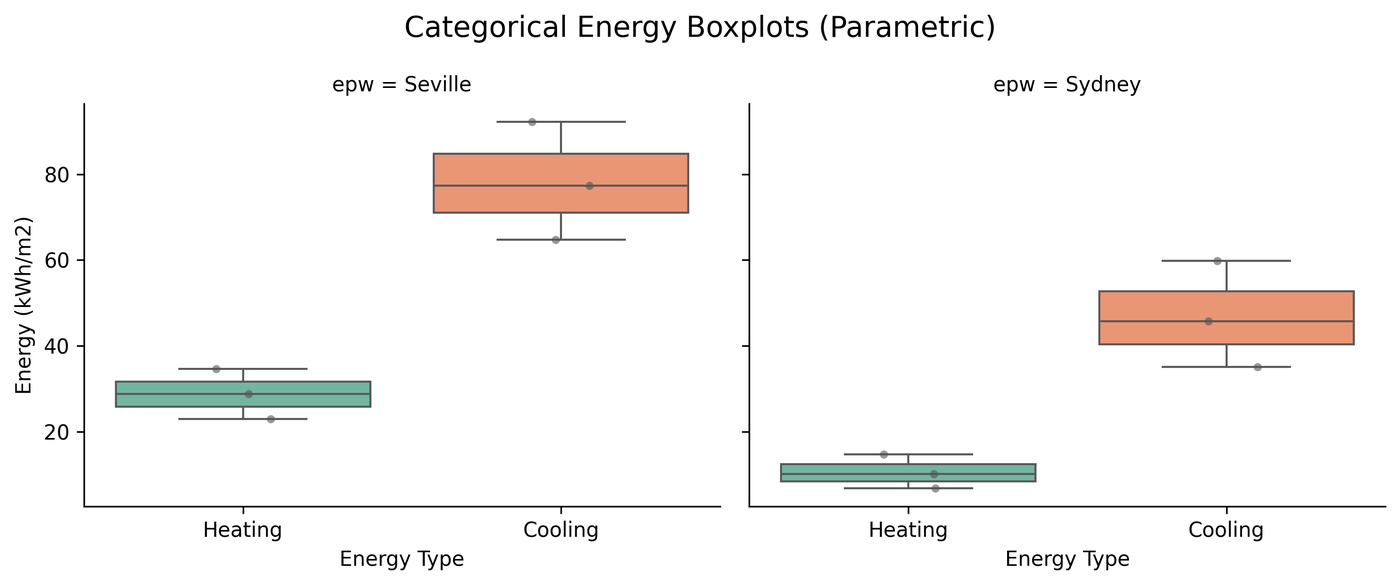

In [3]:

parametric = ParametricSimulation()

parametric.load_outputs_parametric(json_path=str(parametric_json))
print("Loaded parametric rows:", len(parametric.outputs_param_simulation))

parametric.get_hourly_df(start_date="2024-01-01 01", normalize_per_m2=False)
print("Parametric hourly shape:", parametric.outputs_param_simulation_hourly.shape)

parametric.get_monthly_df(start_date="2024-01-01 01", normalize_per_m2=False)
print("Parametric monthly shape:", parametric.outputs_param_simulation_monthly.shape)

# Annual, hourly and monthly tables in kWh/m2.
parametric.set_building_floor_area(mode="custom", custom_area=FLOOR_AREA_M2)
parametric.normalize_outputs()
print("All tables normalized:", parametric.outputs_normalized)

parametric.plot_categorical_boxplots(
    df_source="parametric",
    col="epw",
    out_dir=str(PLOTS_OUT_DIR),
    normalize_per_m2=False,
)
print("Parametric boxplots generated.")

# Figure saved by plot_categorical_boxplots.
for figure in sorted(Path(PLOTS_OUT_DIR).glob("plot_categorical_boxplots_*.png")):
    display(Image(filename=str(figure)))


## Post-processing: prepare hourly dataframe and plotting configuration

Create figures for interpretation and reporting.

This section converts tabular outputs into visual diagnostics for interpretation. Verify axes, filters, and grouping dimensions to ensure valid comparisons.

Key arguments used in this cell and why they matter:
- `json_path`: path to the result file to load.
- `only_pareto_optimal`: whether analysis is restricted to non-dominated rows.
- `skip_confirmation`: skips interactive confirmation prompts.
- `start_date`: start timestamp used for time indexing.
- `normalize_per_m2`: whether results are normalized by floor area.
- `out_dir`: output folder for generated artifacts and results.

Variables created in this cell:
- `optim`: reused in subsequent workflow blocks.

What to verify right after running this cell:
- Open exported figures and verify labels, grouping, and normalization settings.
- Confirm output files were saved in the expected folder.

  [info] idf_backup_path restored: nb07_basic_optimization_results\accim_idf_backup_OSM_TestResidentialUnit_v01_onlygeometry_SchNatVent_v2520_high_performance_pre_optimisation_20261016_180933.idf
  [info] simulation_summary updated for optimisation after load_outputs_optimisation.
Loaded optimisation rows: 16
[get_hourly_df_optimisation] Expanding…
  Simulations selected : 9
  Hourly steps per sim : 8760
  Hourly output columns: 2  → ['Cooling:Electricity [J](Hourly)', 'Heating:Electricity [J](Hourly)']
  Expanded shape       : ~78,840 rows × 12 cols
  Approx. memory       : ~7.6 MB
Optimisation hourly shape: (78840, 12)


Optimisation monthly shape: (108, 11)


  Parallel coordinates plot saved: nb09_postprocessing_plots\plot_parallel_coordinates_Seville.png


  Parallel coordinates plot saved: nb09_postprocessing_plots\plot_parallel_coordinates_Sydney.png
Parallel coordinates plot generated.


  Pairwise scatter matrix saved: nb09_postprocessing_plots\plot_pairwise_scatter_matrix_Seville.png


  Pairwise scatter matrix saved: nb09_postprocessing_plots\plot_pairwise_scatter_matrix_Sydney.png
Pairwise scatter matrix generated.


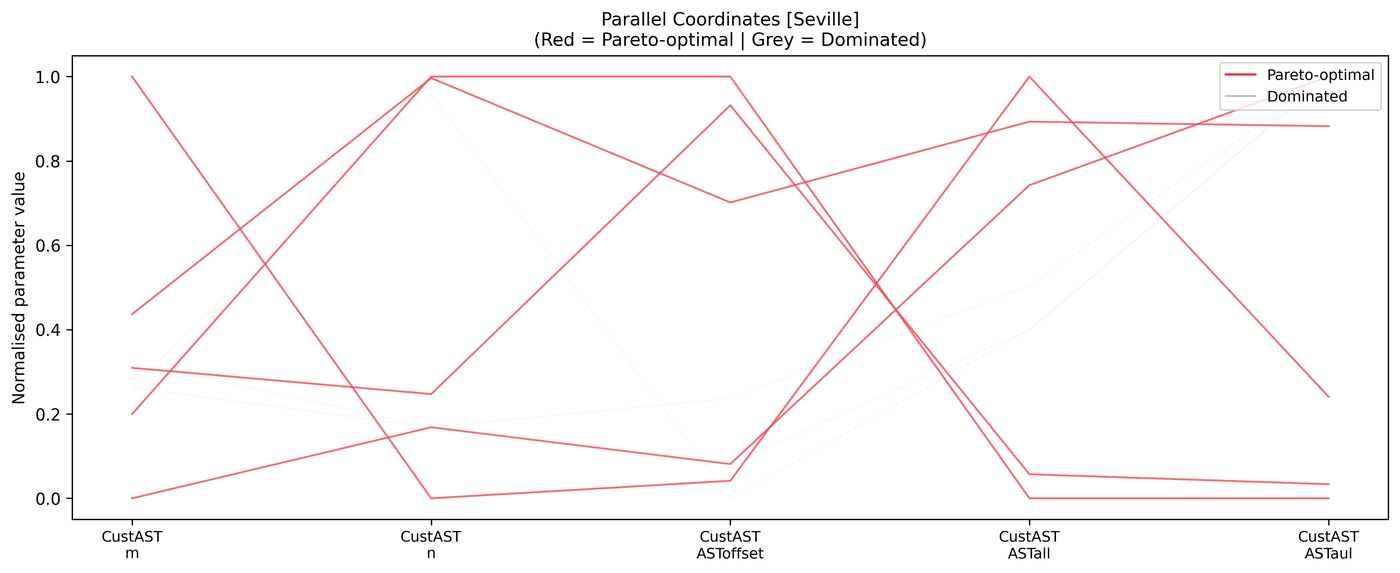

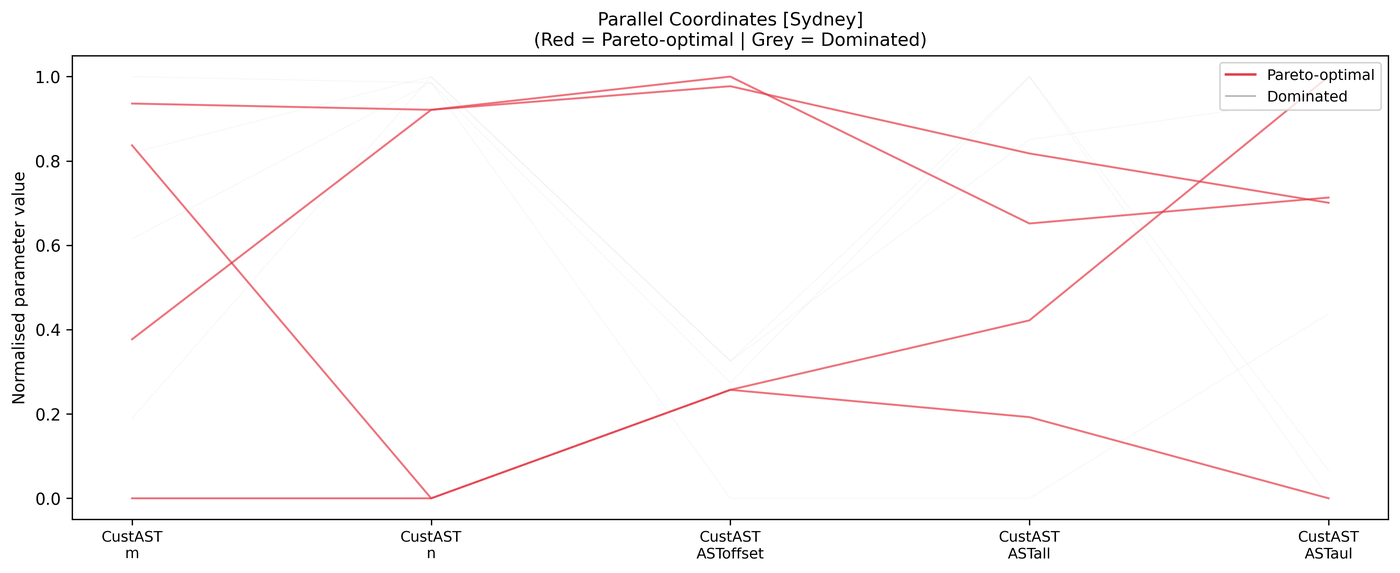

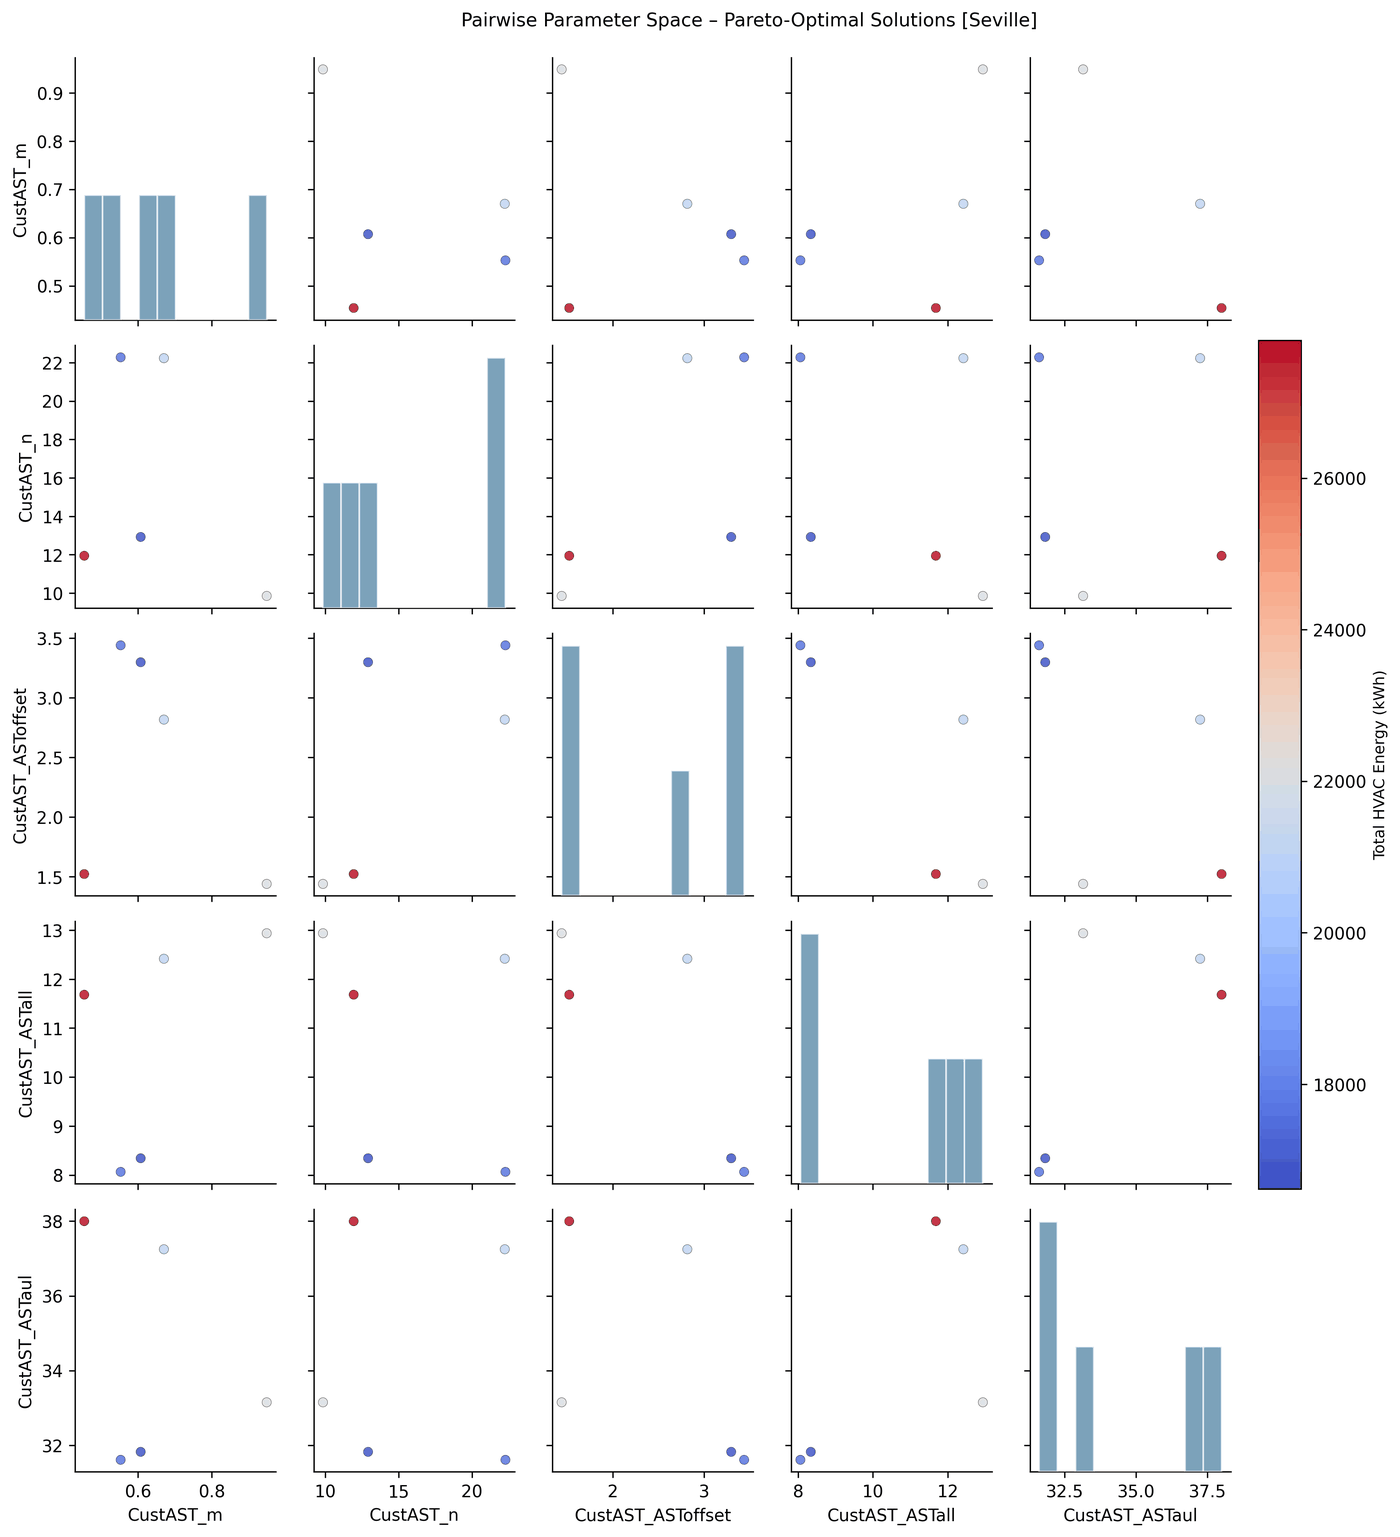

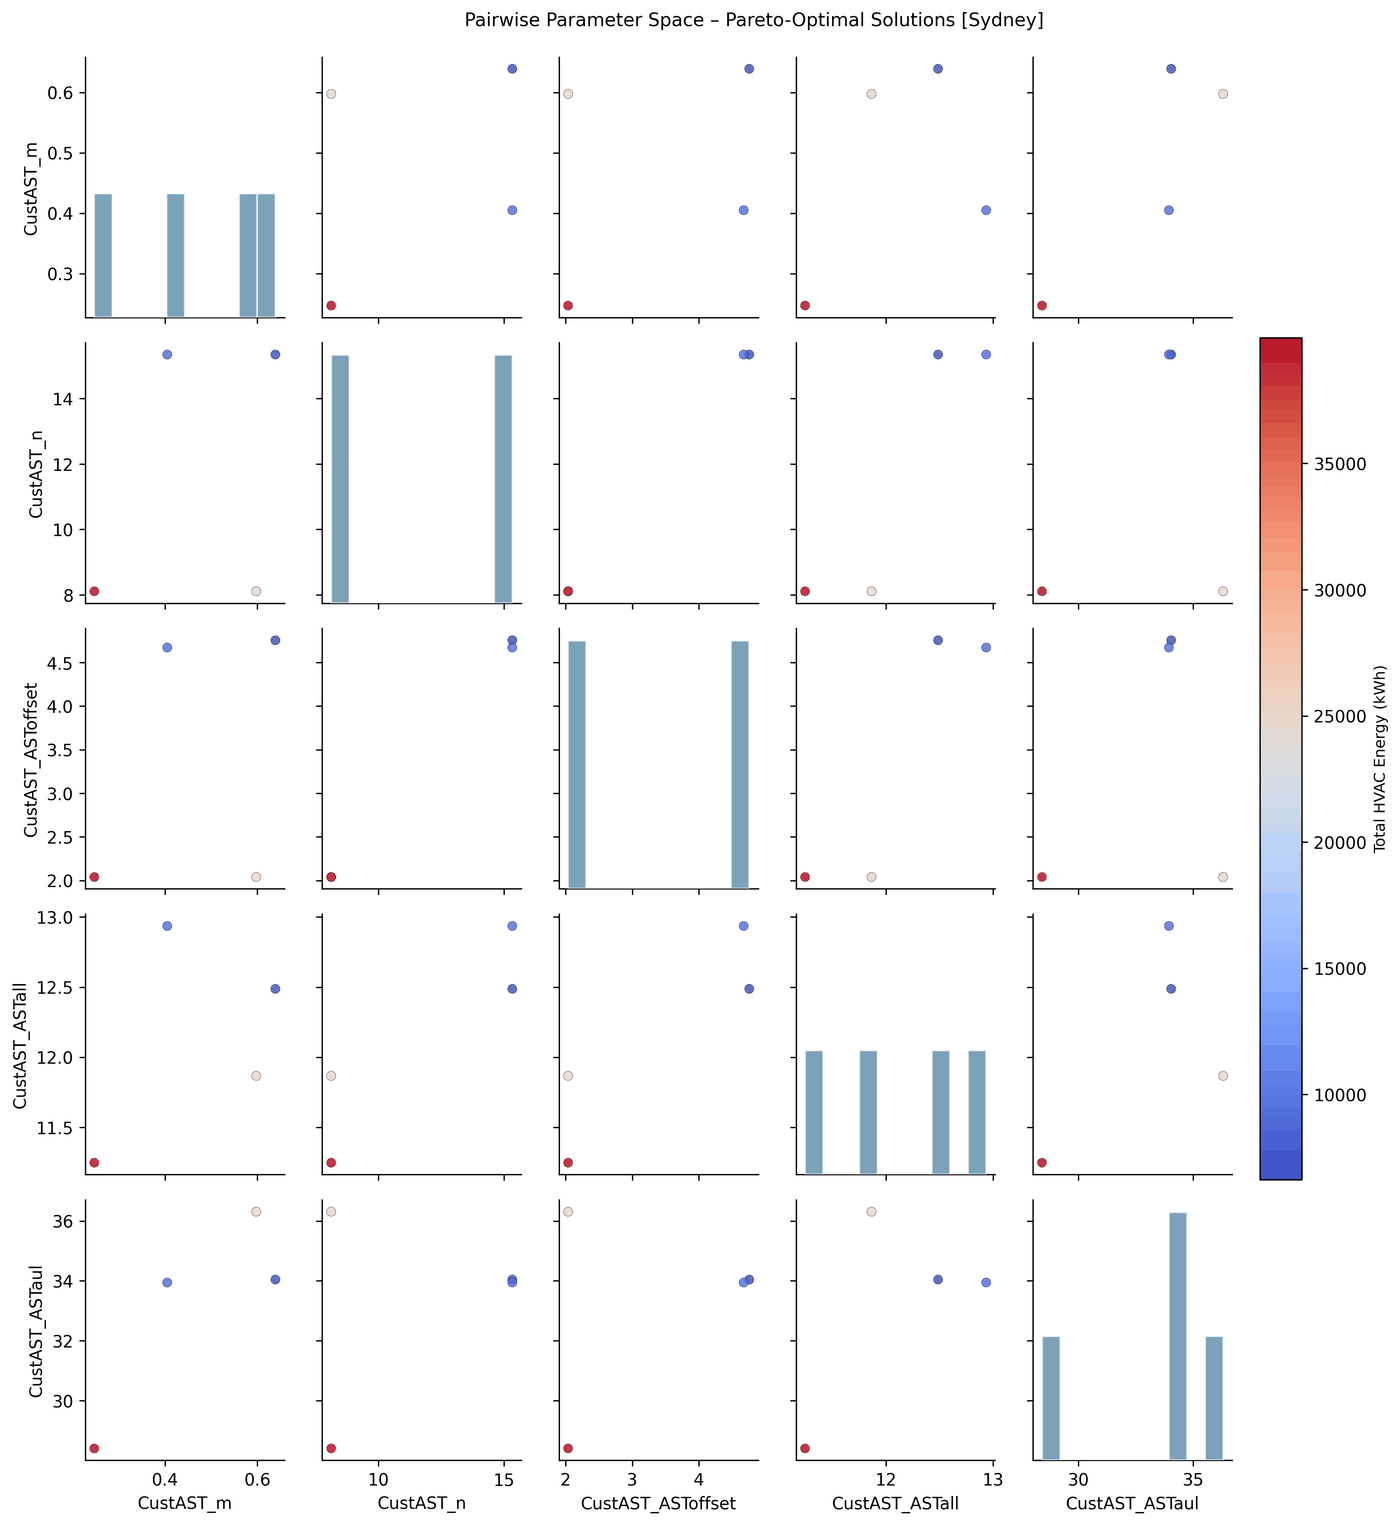

In [4]:

optim = OptimisationSimulation()

optim.load_outputs_optimisation(json_path=str(optim_json))
print("Loaded optimisation rows:", len(optim.outputs_optimisation))

optim.get_hourly_df_optimisation(
    only_pareto_optimal=True,
    skip_confirmation=True,
    start_date="2024-01-01 01",
    normalize_per_m2=False,
)
print("Optimisation hourly shape:", optim.outputs_optimisation_hourly.shape)

optim.get_monthly_df_optimisation(start_date="2024-01-01 01", normalize_per_m2=False)
print("Optimisation monthly shape:", optim.outputs_optimisation_monthly.shape)

optim.plot_parallel_coordinates(out_dir=str(PLOTS_OUT_DIR))
print("Parallel coordinates plot generated.")

optim.plot_pairwise_scatter_matrix(out_dir=str(PLOTS_OUT_DIR), normalize_per_m2=False)
print("Pairwise scatter matrix generated.")

# Figures saved by plot_parallel_coordinates and plot_pairwise_scatter_matrix, one per EPW.
for figure in sorted(Path(PLOTS_OUT_DIR).glob("plot_parallel_coordinates_*.png")):
    display(Image(filename=str(figure)))
for figure in sorted(Path(PLOTS_OUT_DIR).glob("plot_pairwise_scatter_matrix_*.png")):
    display(Image(filename=str(figure)))


### Reading the result

Check the figures above, also saved in the output folder: filters, grouping, and labels should match your intended interpretation.